    # Concise Temperature Forecasting Project

Predict temperature six hours ahead from 24 hourly observations. Run each step and commit after successful execution.

Data Source: [MPI-BGC Beutenberg](https://weather.bgc-jena.mpg.de/weather_data.html), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

# 1. Environment and Setup
Fix model settings and create result folders.

**Run modes.** `RETRAIN = True` (default) runs the full pipeline from scratch: about 45 minutes on a CPU, of which about 40 minutes is the feature ablation in section 15.

`RETRAIN = False` redraws every table and figure without training. Sections 6–9 skip `train_model` and section 10 reloads the saved models in `models/` together with their saved training records and histories in `outputs/`. Section 15 likewise reloads the most recent completed ablation run instead of retraining. To use it: set `RETRAIN = False` and choose *Run All* (about 2–3 minutes in total). The numbers are identical to a full run because the saved models come from that run and training is deterministic (seed 504, TensorFlow op determinism). Use a full run before submission.


In [1]:
import os
import tempfile
from pathlib import Path

# Keep Windows temporary files in the project.
Path(".runtime").mkdir(exist_ok=True)
tempfile.tempdir = str(Path(".runtime").resolve())
os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_NUM_INTRAOP_THREADS"] = "4"
os.environ["TF_NUM_INTEROP_THREADS"] = "2"

import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
import tensorflow as tf
import truststore
truststore.inject_into_ssl()
plt.style.use("default")  # ignore the editor's dark theme so saved figures are white
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

SEED, LOOKBACK, HORIZON = 504, 24, 6
FEATURES = ["T (degC)", "p (mbar)", "rh (%)", "wv (m/s)"]
RETRAIN = True  # False: reuse saved models and only redraw tables and figures (see the run modes above)
for folder in ["data", "outputs", "models", "figures"]:
    Path(folder).mkdir(exist_ok=True)
tf.config.experimental.enable_op_determinism()
CONFIG = {"seed": SEED, "lookback": LOOKBACK, "horizon": HORIZON,
          "features": FEATURES, "learning_rate": 0.001, "batch_size": 64,
          "max_epochs": 30, "patience": 5}
Path("outputs/config.json").write_text(json.dumps(CONFIG, indent=2), encoding="utf-8")
print("Runtime versions:", keras.__version__, tf.__version__)

Runtime versions: 3.15.1 2.21.0


# 2. Download and clean
Source: MPI-BGC Beutenberg, CC BY 4.0. Check duplicate conflicts and mask invalid values.

In [2]:
from urllib.request import urlretrieve
from zipfile import ZipFile

names = [f"mpi_roof_{year}{half}" for year in range(2018, 2024) for half in "ab"]
names += ["mpi_roof_2024", "mpi_roof_2025"]
parts = []
for name in names:
    path = Path("data") / f"{name}.zip"
    if not path.exists():
        urlretrieve(f"https://www.bgc-jena.mpg.de/wetter/data/{name}.zip", path)
    with ZipFile(path) as archive:
        with archive.open(f"{name}.csv") as file:
            parts.append(pd.read_csv(file, encoding="latin-1"))

data = pd.concat(parts, ignore_index=True)
data["Date Time"] = pd.to_datetime(data["Date Time"], format="%d.%m.%Y %H:%M:%S")
# Resolve conflicting measurements before deduplication.
repeated = data[data["Date Time"].duplicated(keep=False)]
measurements = data.columns.drop("Date Time")
assert not repeated.groupby("Date Time")[measurements].nunique(dropna=False).gt(1).any().any()
observed = (data.sort_values("Date Time").drop_duplicates("Date Time")
            .set_index("Date Time")[FEATURES].copy())
observed = observed.replace([-9999, np.inf, -np.inf], np.nan)
observed.loc[observed["p (mbar)"] <= 0, "p (mbar)"] = np.nan
observed.loc[~observed["rh (%)"].between(0, 100), "rh (%)"] = np.nan
observed.loc[observed["wv (m/s)"] < 0, "wv (m/s)"] = np.nan
print("Raw/deduplicated rows:", len(data), len(observed))
display(observed.isna().sum().to_frame("Missing count"))

Raw/deduplicated rows: 420782 420631


,Missing count
T (degC),0
p (mbar),0
rh (%),0
wv (m/s),1


# 3. Continuous hourly data

Exact-hour values summarize the preceding ten minutes; retain missing hours without filling. Keep station clock labels.

In [3]:
# Select exact timestamps rather than every sixth row.
hourly_index = pd.date_range(observed.index.min().ceil("h"), observed.index.max().floor("h"), freq="h")
hourly = observed.reindex(hourly_index)
hourly.index.name = "Date Time"
hourly.to_csv("outputs/hourly_observations.csv")
print("Hourly slots/missing hours:", len(hourly), hourly.isna().all(axis=1).sum())

Hourly slots/missing hours: 70128 22


# 4. Scaling, windows and splits

Inputs t-23h..t, target t+6h; split by target year with a shared four-feature mask.

In [4]:
# Fit on training hours only; keep targets in Celsius.
train_hours = hourly.loc[(hourly.index.year >= 2018) & (hourly.index.year <= 2023)]
mean, std = train_hours.mean(), train_hours.std(ddof=0)
assert np.isfinite(std).all() and (std > 0).all()
scaler = {"features": FEATURES, "means": mean.to_dict(), "stds": std.to_dict()}
Path("outputs/training_scaler.json").write_text(json.dumps(scaler, indent=2), encoding="utf-8")
scaled = ((hourly - mean) / std).to_numpy(dtype=np.float32)

ends = np.arange(LOOKBACK - 1, len(hourly) - HORIZON)
X = np.stack([scaled[t - LOOKBACK + 1:t + 1] for t in ends])
y = hourly[FEATURES[0]].to_numpy()[ends + HORIZON].astype(np.float32)
latest = hourly[FEATURES[0]].to_numpy()[ends].astype(np.float32)
targets = hourly.index[ends + HORIZON]
# Check inputs/targets, not unused t+1..t+5.
valid = np.isfinite(X).all(axis=(1, 2)) & np.isfinite(y)
splits = {}
for name, years in {"train": (2018, 2023), "val": (2024, 2024), "test": (2025, 2025)}.items():
    keep = valid & (targets.year >= years[0]) & (targets.year <= years[1])
    splits[name] = {"X": X[keep], "y": y[keep], "latest": latest[keep], "times": targets[keep]}
display(pd.DataFrame({name: {"Samples": len(part["y"])} for name, part in splits.items()}).T)

,Samples
train,52449
val,8784
test,8760


# 5. Persistence validation baseline

Evaluate validation first; test after all models are trained.

In [5]:
def metrics(y, prediction):
    """Errors in degrees Celsius."""
    error = np.asarray(prediction, dtype=float) - np.asarray(y, dtype=float)
    return {"samples": len(error), "mae_c": float(np.abs(error).mean()),
            "rmse_c": float(np.sqrt(np.square(error).mean())), "bias_c": float(error.mean())}

baseline = metrics(splits["val"]["y"], splits["val"]["latest"])
pd.DataFrame([baseline], index=["persistence"]).to_csv("outputs/baseline_validation.csv")
print("Persistence validation:", baseline)

Persistence validation: {'samples': 8784, 'mae_c': 3.3267588744085037, 'rmse_c': 4.36269431262839, 'bias_c': 0.00519922586498894}


# 6. Temperature Dense and training helper

Apply the same plan to all models; restore the best validation-MSE weights.

In [6]:
def dataset(X, y=None, training=False):
    """Batches with bounded threading."""
    ds = tf.data.Dataset.from_tensor_slices(X if y is None else (X, y))
    if training:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 1
    options.threading.max_intra_op_parallelism = 1
    return ds.with_options(options).batch(64).prefetch(1)

records = {}
def train_model(name, multivariate=False, recurrent=False):
    """Train and save the best model."""
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    features = 4 if multivariate else 1
    layers = [keras.layers.Input((LOOKBACK, features))]
    layers += ([keras.layers.GRU(32)] if recurrent else
               [keras.layers.Flatten(), keras.layers.Dense(32, activation="relu")])
    model = keras.Sequential(layers + [keras.layers.Dense(1)])
    model.compile(optimizer=keras.optimizers.Adam(0.001), loss="mse", metrics=["mae"])
    train, val = splits["train"], splits["val"]
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    start = time.perf_counter()
    history = model.fit(dataset(train["X"][:, :, :features], train["y"], True),
                        validation_data=dataset(val["X"][:, :, :features], val["y"]),
                        epochs=30, callbacks=[stop], shuffle=False, verbose=2)
    seconds = time.perf_counter() - start
    model.save(f"models/{name}.keras")
    pd.DataFrame(history.history).to_csv(f"outputs/history_{name}.csv", index=False)
    prediction = model.predict(dataset(val["X"][:, :, :features]), verbose=0).ravel()
    records[name] = {**metrics(val["y"], prediction), "parameters": model.count_params(),
                     "training_seconds": seconds, "best_epoch": int(np.argmin(history.history["val_loss"]) + 1)}
    pd.DataFrame(records).T.to_csv("outputs/validation_results.csv")
    plt.figure(figsize=(6, 3))
    plt.plot(history.history["loss"], label="Training")
    plt.plot(history.history["val_loss"], label="Validation")
    plt.xlabel("Epoch"); plt.ylabel("MSE (°C²)"); plt.legend()
    plt.tight_layout(); plt.savefig(f"figures/history_{name}.png", dpi=200); plt.show()
    print(name, "Validation:", records[name])

if RETRAIN:
    train_model("dense_temp")

# 7. Temperature GRU

Use identical temperature inputs and training settings.

In [7]:
if RETRAIN:
    train_model("gru_temp", recurrent=True)

# 8. Multivariate GRU

Add observed pressure, humidity and wind speed.

In [8]:
if RETRAIN:
    train_model("gru_multi", multivariate=True, recurrent=True)

# 9. Multivariate Dense control

Use the same temperature, pressure, humidity and wind-speed inputs as multivariate GRU: `24×4 -> Flatten -> Dense(32, ReLU) -> Dense(1)`. Keep the same splits, training-period normalization, seed and early-stopping rules.

| Model | Temperature only | Four variables |
| --- | --- | --- |
| Dense | `dense_temp` | `dense_multi` |
| GRU | `gru_temp` | `gru_multi` |

This control checks whether added variables also help Dense, and how GRU compares with Dense using the same four inputs. Evaluation determines the outcome; parameter counts still differ.

This is a fixed extension after the original three-model evaluation, without tuning from the new test scores.

In [9]:
# Use the same training helper with four input variables.
if RETRAIN:
    train_model("dense_multi", multivariate=True)

# 10. Shared test evaluation
Evaluate identical 2025 targets after fixing the plan; do not select further settings from test scores.
Shared evaluation includes persistence and all four learned models.

With `RETRAIN = False`, the training records (parameters, training time, best epoch) are read from `outputs/validation_results.csv` and the training curves are redrawn from `outputs/history_*.csv`; the saved models are loaded below in both modes.

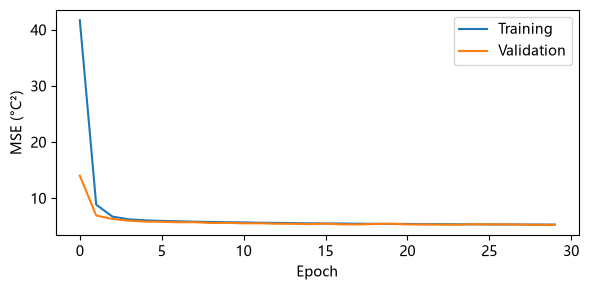

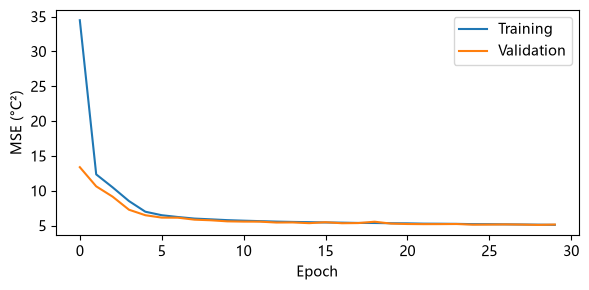

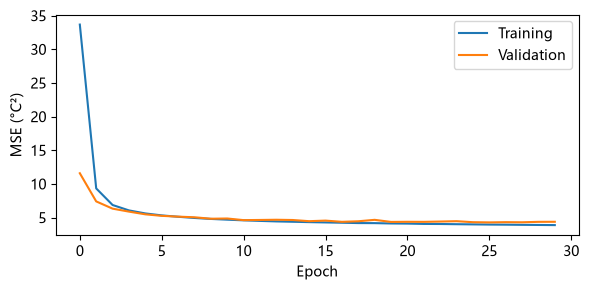

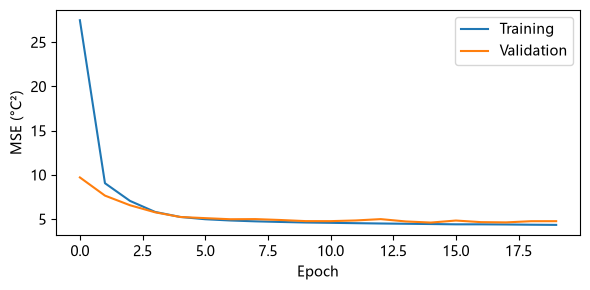

RETRAIN = False: reusing saved models ['dense_temp', 'gru_temp', 'gru_multi', 'dense_multi']


,samples,mae_c,rmse_c,bias_c,parameters,training_seconds
model,,,,,,
persistence,8760,3.560174,4.680442,-0.002009,0,0.000000
dense_temp,8760,1.792809,2.332945,0.016207,833,16.913411
gru_temp,8760,1.770988,2.307551,-0.048988,3393,96.095646
gru_multi,8760,1.604429,2.090741,0.248562,3681,82.978616
dense_multi,8760,1.663471,2.152831,0.108781,3137,11.402932


In [10]:
if not RETRAIN:
    # Fast mode: rebuild the training records of the last full run and redraw its training curves.
    saved = pd.read_csv("outputs/validation_results.csv", index_col=0)
    records = {name: {**row.to_dict(), "parameters": int(row.parameters)} for name, row in saved.iterrows()}
    for name in records:
        history = pd.read_csv(f"outputs/history_{name}.csv")
        plt.figure(figsize=(6, 3))
        plt.plot(history["loss"], label="Training")
        plt.plot(history["val_loss"], label="Validation")
        plt.xlabel("Epoch"); plt.ylabel("MSE (°C²)"); plt.legend()
        plt.tight_layout(); plt.savefig(f"figures/history_{name}.png", dpi=200); plt.show()
    print("RETRAIN = False: reusing saved models", list(records))

test = splits["test"]
predictions = pd.DataFrame({"target_time": test["times"], "observed_c": test["y"],
                            "persistence": test["latest"]})
for name in records:
    model = keras.saving.load_model(f"models/{name}.keras", compile=False)
    count = model.input_shape[-1]
    predictions[name] = model.predict(dataset(test["X"][:, :, :count]), verbose=0).ravel()
rows = []
for name in ["persistence"] + list(records):
    record = records.get(name, {"parameters": 0, "training_seconds": 0})
    rows.append({"model": name, **metrics(predictions.observed_c, predictions[name]),
                 "parameters": record["parameters"], "training_seconds": record["training_seconds"]})
results = pd.DataFrame(rows).set_index("model")
predictions.to_csv("outputs/test_predictions.csv", index=False)
results.to_csv("outputs/test_results.csv")
display(results)

# 11. Error analysis and paired intervals
Groups are post-test diagnostics; daily intervals exclude retraining uncertainty.

Retain the original three intervals and add paired MAE-difference intervals for multivariate Dense versus temperature Dense, and multivariate GRU versus multivariate Dense. Daily intervals describe test-date uncertainty for frozen models and exclude retraining variability.

Observed-target temperature bands are post-test diagnostics. A larger warm-group gain is an observation from this run; between-group significance and causal weather mechanisms have not been tested.

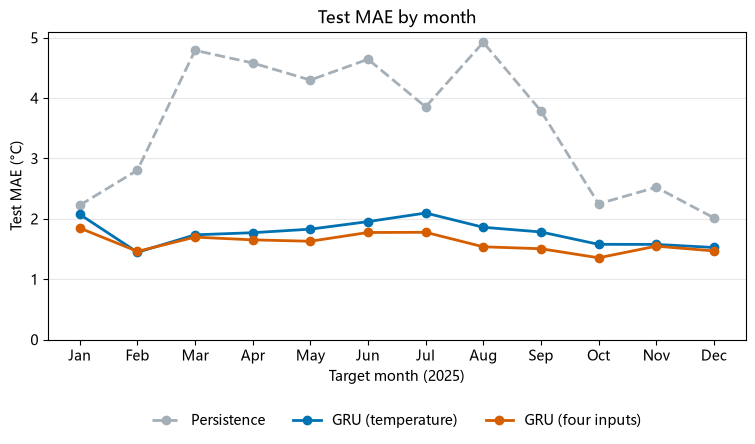

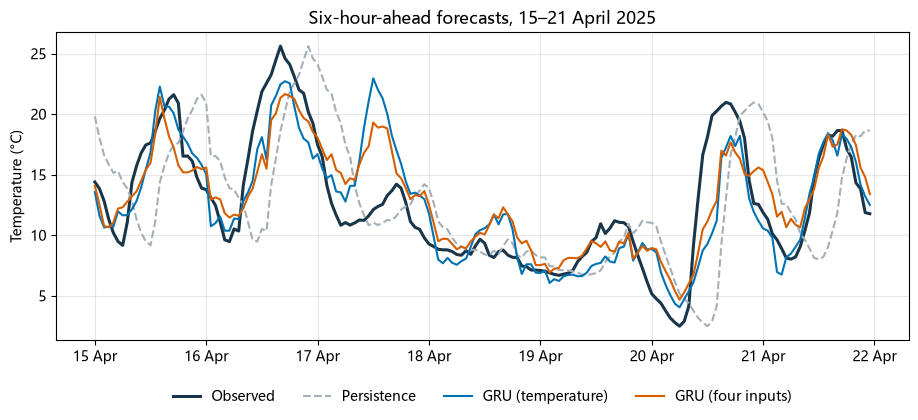

,samples,persistence,dense_temp,gru_temp,gru_multi,dense_multi
observed_c,,,,,,
<0°C,891,2.444568,1.706584,1.671644,1.635926,1.636507
0-<10°C,3259,2.834925,1.675097,1.641128,1.537961,1.590473
10-<20°C,3564,3.873460,1.751995,1.723034,1.561786,1.611432
≥20°C,1046,5.702658,2.372077,2.423602,1.929991,2.091190


,candidate,reference,mae_difference_c,reduction_pct,ci_low_c,ci_high_c
0,gru_temp,dense_temp,-0.021822,1.217170,-0.044434,0.000153
1,gru_multi,gru_temp,-0.166558,9.404837,-0.214215,-0.113192
2,gru_multi,persistence,-1.955744,54.933961,-2.155693,-1.771831
3,dense_multi,dense_temp,-0.129338,7.214266,-0.171656,-0.086688
4,gru_multi,dense_multi,-0.059042,3.549326,-0.092662,-0.026135


Temperature GRU vs Temperature Dense: MAE difference = -0.0218°C; MAE reduction = +1.22%; 95% daily CI = [-0.0444, +0.0002]°C; Interval includes zero
Multivariate GRU vs Temperature GRU: MAE difference = -0.1666°C; MAE reduction = +9.40%; 95% daily CI = [-0.2142, -0.1132]°C; Interval excludes zero
Multivariate GRU vs Persistence: MAE difference = -1.9557°C; MAE reduction = +54.93%; 95% daily CI = [-2.1557, -1.7718]°C; Interval excludes zero
Multivariate Dense vs Temperature Dense: MAE difference = -0.1293°C; MAE reduction = +7.21%; 95% daily CI = [-0.1717, -0.0867]°C; Interval excludes zero
Multivariate GRU vs Multivariate Dense: MAE difference = -0.0590°C; MAE reduction = +3.55%; 95% daily CI = [-0.0927, -0.0261]°C; Interval excludes zero
Observed temperature ≥20°C: N = 1046, Temperature GRU MAE = 2.424°C, Multivariate GRU MAE = 1.930°C, MAE reduction = 20.4%; Overall reduction = 9.4%.


In [11]:
names = ["persistence"] + list(records)
errors = predictions[names].astype(float).sub(predictions.observed_c.astype(float), axis=0)
absolute = errors.abs()
absolute.index = pd.DatetimeIndex(predictions.target_time)

monthly = absolute.groupby(absolute.index.month).mean()
monthly.to_csv("outputs/monthly_mae.csv")

bands = pd.cut(
    predictions.observed_c,
    [-np.inf, 0, 10, 20, np.inf],
    right=False,
    labels=["<0°C", "0-<10°C", "10-<20°C", "≥20°C"]
)
band_errors = absolute.reset_index(drop=True).groupby(bands, observed=False).mean()
band_errors.insert(0, "samples", bands.value_counts(sort=False))
band_errors.to_csv("outputs/temperature_band_mae.csv")

worst = []
for name in names:
    part = predictions.loc[
        errors[name].abs().nlargest(10).index,
        ["target_time", "observed_c", name]
    ].copy()
    part["model"] = name
    part = part.rename(columns={name: "predicted_c"})
    part["error_c"] = part.predicted_c - part.observed_c
    worst.append(part)
pd.concat(worst).to_csv("outputs/worst_errors.csv", index=False)

import matplotlib.dates
NICE = {"persistence": "Persistence", "dense_temp": "Dense (temperature)", "gru_temp": "GRU (temperature)",
        "dense_multi": "Dense (four inputs)", "gru_multi": "GRU (four inputs)"}
STYLE = {"persistence": ("#A5AFB7", "--"), "gru_temp": ("#0072B2", "-"), "gru_multi": ("#D55E00", "-")}

# Monthly MAE: persistence and the two GRUs (Dense models omitted for readability).
fig, ax = plt.subplots(figsize=(9, 4))
for name, (colour, line) in STYLE.items():
    ax.plot(monthly.index, monthly[name], marker="o", color=colour, linestyle=line, linewidth=2, label=NICE[name])
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                             "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set(xlabel="Target month (2025)", ylabel="Test MAE (°C)", title="Test MAE by month", ylim=(0, None))
ax.grid(axis="y", alpha=.3)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(.5, -.2))
fig.savefig("figures/monthly_mae.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

# Forecast trace for a week that contains two of the largest failures (17 and 20 April 2025).
week = predictions.set_index("target_time").loc["2025-04-15":"2025-04-21"]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(week.index, week.observed_c, color="#193549", linewidth=2.2, label="Observed")
for name, (colour, line) in STYLE.items():
    ax.plot(week.index, week[name], color=colour, linestyle=line, linewidth=1.5, label=NICE[name])
ax.set(ylabel="Temperature (°C)", title="Six-hour-ahead forecasts, 15–21 April 2025")
ax.grid(alpha=.3)
ax.xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%d %b"))
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(.5, -.12))
fig.savefig("figures/prediction_trace.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

display(band_errors)

# Resample complete days, weighted by sampled observation counts.
days = absolute.index.normalize()
sums = absolute.groupby(days).sum()
counts = absolute.groupby(days).size().to_numpy()
draws = np.random.default_rng(SEED).integers(
    0, len(counts), size=(2000, len(counts))
)

comparisons = []

# Two new comparisons complete the architecture/input controls.
pairs = [
    ("gru_temp", "dense_temp"),
    ("gru_multi", "gru_temp"),
    ("gru_multi", "persistence"),
    ("dense_multi", "dense_temp"),
    ("gru_multi", "dense_multi")
]

for candidate, reference in pairs:
    daily_difference = (sums[candidate] - sums[reference]).to_numpy()
    sampled = daily_difference[draws].sum(axis=1) / counts[draws].sum(axis=1)
    low, high = np.quantile(sampled, [0.025, 0.975])
    comparisons.append({
        "candidate": candidate,
        "reference": reference,
        "mae_difference_c": float(
            absolute[candidate].mean() - absolute[reference].mean()
        ),
        "reduction_pct": float(
            100 * (1 - absolute[candidate].mean() / absolute[reference].mean())
        ),
        "ci_low_c": float(low),
        "ci_high_c": float(high)
    })

comparison_results = pd.DataFrame(comparisons)
comparison_results.to_csv("outputs/paired_daily_bootstrap.csv", index=False)
display(comparison_results)

# Interpret the new controls without assuming improvement.
labels = {
    "dense_temp": "Temperature Dense",
    "dense_multi": "Multivariate Dense",
    "gru_temp": "Temperature GRU",
    "gru_multi": "Multivariate GRU",
    "persistence": "Persistence"
}

for row in comparison_results.itertuples():
    interval = (
        "Interval includes zero"
        if row.ci_low_c <= 0 <= row.ci_high_c
        else "Interval excludes zero"
    )
    print(
        f"{labels[row.candidate]} vs {labels[row.reference]}: "
        f"MAE difference = {row.mae_difference_c:+.4f}°C; "
        f"MAE reduction = {row.reduction_pct:+.2f}%; "
        f"95% daily CI = [{row.ci_low_c:+.4f}, {row.ci_high_c:+.4f}]°C; "
        f"{interval}"
    )

# Recompute warm-group and overall GRU gains.
warm = band_errors.loc["≥20°C"]
warm_gain = 100 * (1 - warm["gru_multi"] / warm["gru_temp"])
overall_gain = 100 * (
    1 - results.loc["gru_multi", "mae_c"] / results.loc["gru_temp", "mae_c"]
)

print(
    f"Observed temperature ≥20°C: N = {int(warm['samples'])}, "
    f"Temperature GRU MAE = {warm['gru_temp']:.3f}°C, "
    f"Multivariate GRU MAE = {warm['gru_multi']:.3f}°C, "
    f"MAE reduction = {warm_gain:.1f}%; "
    f"Overall reduction = {overall_gain:.1f}%."
)

# 12. Overall comparison and zoomed view

Use `results` from Step 10. The left panel shows all five methods with zero-based bars (0-4°C). The right panel uses zoomed dots (1.50-1.95°C) to show the MAE changes after adding variables to each architecture. Values and reductions come from this run.

Output: `figures/overall_mae_comparison.png`, 3200×1800, 16:9.

After completing the preceding steps, rerun this cell without retraining.

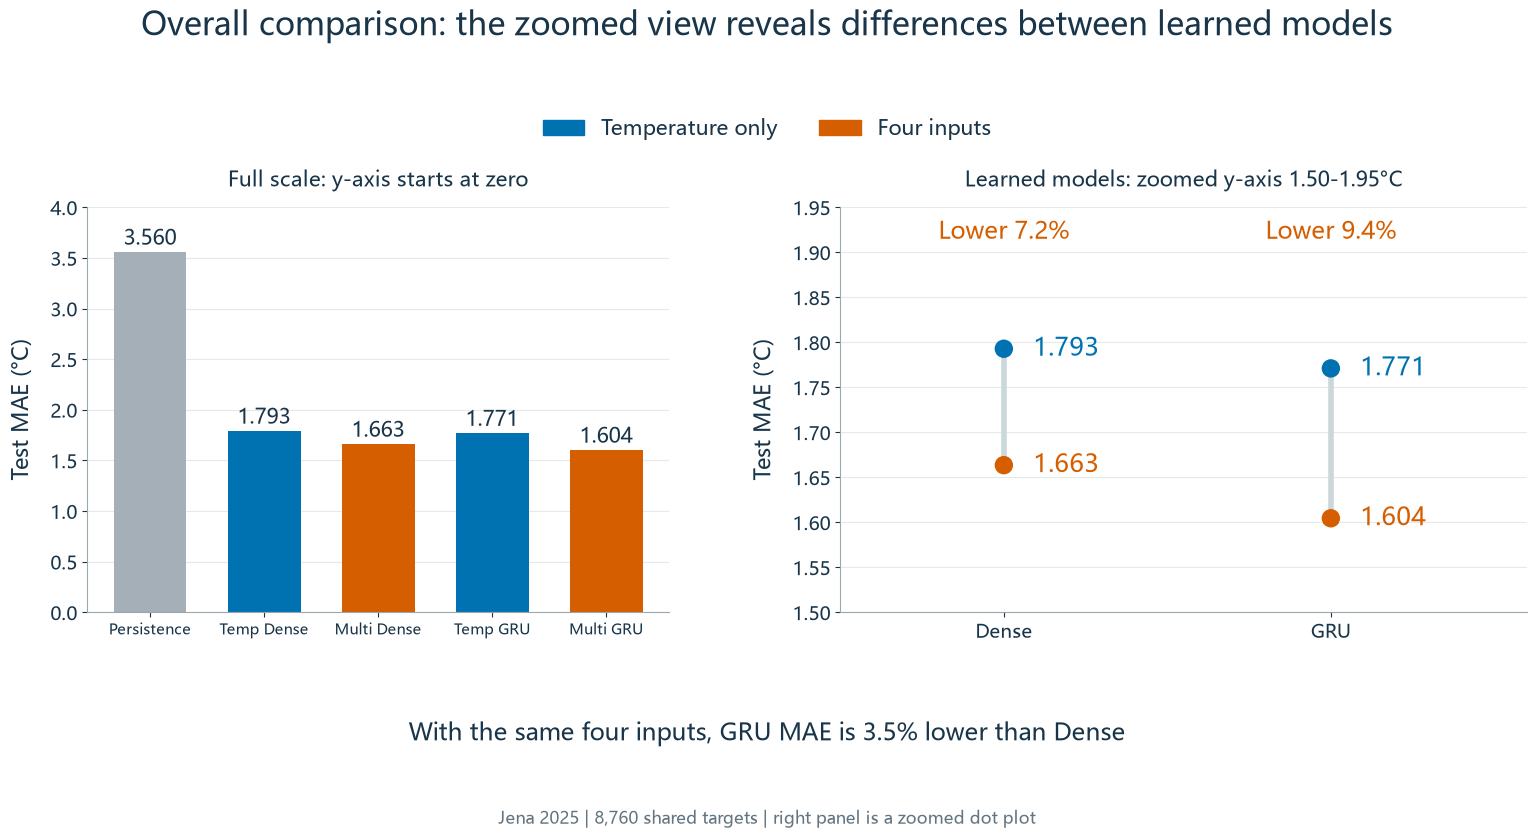

In [12]:
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# Reuse test metrics, save and display the charts.
# Palette shared with the slides: blue = temperature only, vermillion = four inputs, grey = persistence.
INK, BLUE, GREEN, GREY = "#193549", "#0072B2", "#D55E00", "#A5AFB7"
plt.rcParams.update({
    "font.size": 14,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "text.color": INK,
    "legend.labelcolor": INK,
})

def style(ax, ylabel="Test MAE (°C)"):
    """Keep units visible on full-scale and zoomed axes."""
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#E4E9EC", linewidth=0.8)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["bottom", "left"]:
        ax.spines[side].set_color("#9BA6AF")
    ax.tick_params(colors=INK, labelsize=14)
    ax.set_ylabel(ylabel, fontsize=16, color=INK, labelpad=12)


def save(fig, filename):
    """Export a high-resolution 16:9 image."""
    fig.savefig(Path("figures") / filename, dpi=200, facecolor="white")
    plt.show()
    plt.close(fig)


# Keep zero-based bars at left and a labeled zoomed dot plot at right.
models = ["persistence", "dense_temp", "dense_multi", "gru_temp", "gru_multi"]
values = results.loc[models, "mae_c"].to_numpy()

fig, (full, zoom) = plt.subplots(
    1, 2, figsize=(16, 9),
    gridspec_kw={"width_ratios": [1.0, 1.18]}
)
fig.subplots_adjust(left=.075, right=.975, top=.74, bottom=.29, wspace=.27)

fig.suptitle(
    "Overall comparison: the zoomed view reveals differences between learned models",
    fontsize=23, color=INK, y=.96
)
fig.legend(
    handles=[
        Patch(color=BLUE, label="Temperature only"),
        Patch(color=GREEN, label="Four inputs")
    ],
    loc="upper center",
    bbox_to_anchor=(.5, .86),
    ncol=2,
    frameon=False,
    fontsize=15
)

full.bar(
    np.arange(5), values, width=.64,
    color=[GREY, BLUE, GREEN, BLUE, GREEN]
)
full.set_xticks(
    np.arange(5),
    ["Persistence", "Temp Dense", "Multi Dense", "Temp GRU", "Multi GRU"],
    fontsize=11
)
full.set_ylim(0, 4.0)
full.set_yticks(np.arange(0, 4.01, .5))
full.set_title(
    "Full scale: y-axis starts at zero",
    fontsize=15, color=INK, pad=15
)
style(full)
full.tick_params(axis="x", labelsize=11)

for position, value in enumerate(values):
    full.text(
        position, value + .07, f"{value:.3f}",
        ha="center", fontsize=15, color=INK
    )

# Dot positions show MAE without exaggerating cropped bar lengths.
for position, architecture in enumerate(["dense", "gru"]):
    a = float(results.loc[f"{architecture}_temp", "mae_c"])
    b = float(results.loc[f"{architecture}_multi", "mae_c"])
    gain = 100 * (1 - b / a)

    zoom.plot(
        [position, position], [b, a],
        color="#CAD7DB", linewidth=4, zorder=2
    )
    zoom.scatter(
        [position, position], [a, b],
        color=[BLUE, GREEN], s=150, zorder=3
    )
    zoom.text(
        position + .09, a, f"{a:.3f}",
        color=BLUE, fontsize=18, va="center"
    )
    zoom.text(
        position + .09, b, f"{b:.3f}",
        color=GREEN, fontsize=18, va="center"
    )
    zoom.text(
        position, 1.915, f"Lower {gain:.1f}%",
        ha="center", fontsize=17, color=GREEN
    )

zoom.set_xticks([0, 1], ["Dense", "GRU"])
zoom.set_xlim(-.5, 1.6)
zoom.set_ylim(1.50, 1.95)
zoom.set_yticks(np.arange(1.50, 1.951, .05))
zoom.set_title(
    "Learned models: zoomed y-axis 1.50-1.95°C",
    fontsize=15, color=INK, pad=15
)
style(zoom)

architecture_gain = 100 * (
    1 - results.loc["gru_multi", "mae_c"]
    / results.loc["dense_multi", "mae_c"]
)
fig.text(
    .5, .155,
    f"With the same four inputs, GRU MAE is {architecture_gain:.1f}% lower than Dense",
    ha="center", va="center", fontsize=17, color=INK
)
fig.text(
    .5, .055,
    f"Jena 2025 | {int(results.loc['persistence', 'samples']):,} shared targets "
    "| right panel is a zoomed dot plot",
    ha="center", fontsize=12, color="#637581"
)

save(fig, "overall_mae_comparison.png")

## 13. Temperature-band errors and reductions

Use `band_errors` from Step 11. The left panel shows both GRUs' band MAEs with a zoomed y-axis of 1.40-2.65°C. The right panel shows relative reductions on a zero-based 0-25% axis. Groups and counts use actual target temperatures for post-test diagnosis only.

Reduction = `(temperature GRU MAE - multivariate GRU MAE) / temperature GRU MAE × 100%`.

A larger warm-group gain is an observed pattern in this run. Between-band significance and individual variable or weather-mechanism contributions have not been established.

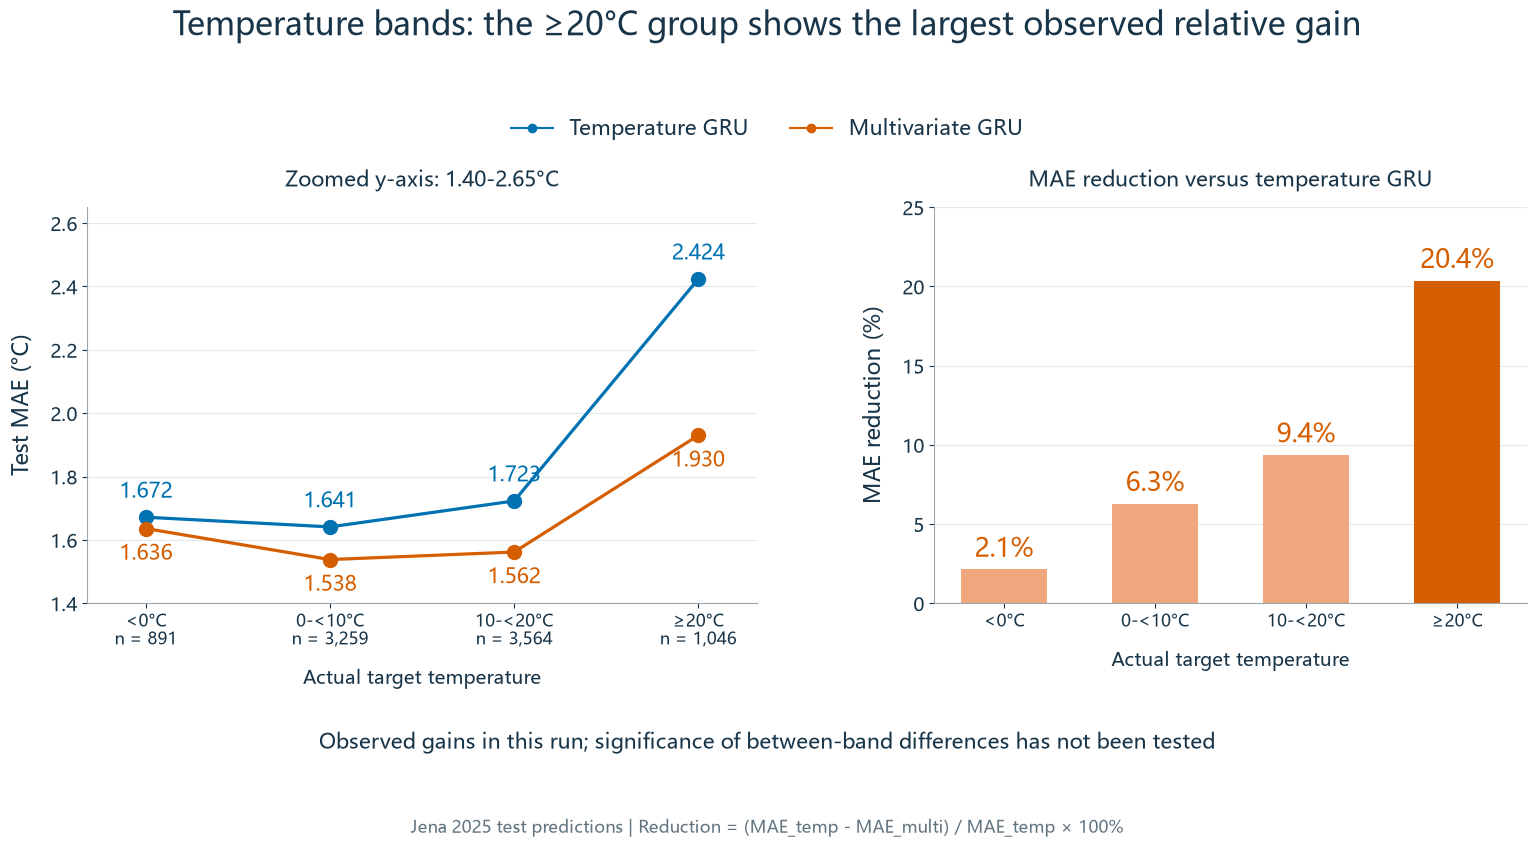

In [13]:
# Pair a zoomed MAE plot with zero-based percentage-reduction bars.
temp = band_errors["gru_temp"].to_numpy()
multi = band_errors["gru_multi"].to_numpy()
gains = 100 * (1 - multi / temp)
x = np.arange(len(band_errors))

fig, (mae, improvement) = plt.subplots(
    1, 2, figsize=(16, 9),
    gridspec_kw={"width_ratios": [1.13, 1.0]}
)
fig.subplots_adjust(left=.075, right=.975, top=.74, bottom=.30, wspace=.28)

fig.suptitle(
    "Temperature bands: the ≥20°C group shows the largest observed relative gain",
    fontsize=23, color=INK, y=.96
)
fig.legend(
    handles=[
        Line2D([0], [0], color=BLUE, marker="o", label="Temperature GRU"),
        Line2D([0], [0], color=GREEN, marker="o", label="Multivariate GRU")
    ],
    loc="upper center",
    bbox_to_anchor=(.5, .86),
    ncol=2,
    frameon=False,
    fontsize=15
)

mae.plot(x, temp, color=BLUE, marker="o", markersize=10, linewidth=2.3)
mae.plot(x, multi, color=GREEN, marker="o", markersize=10, linewidth=2.3)

for i, (a, b) in enumerate(zip(temp, multi)):
    mae.text(
        i, a + .045, f"{a:.3f}",
        ha="center", va="bottom", fontsize=15, color=BLUE
    )
    mae.text(
        i, b - .045, f"{b:.3f}",
        ha="center", va="top", fontsize=15, color=GREEN
    )

mae.set_xticks(
    x,
    [
        f"{label}\nn = {int(count):,}"
        for label, count in zip(band_errors.index, band_errors["samples"])
    ]
)
mae.set_xlim(-.32, 3.32)
mae.set_ylim(1.40, 2.65)
mae.set_yticks(np.arange(1.40, 2.651, .20))
mae.set_title(
    "Zoomed y-axis: 1.40-2.65°C",
    fontsize=15, color=INK, pad=15
)
style(mae)
mae.tick_params(axis="x", labelsize=12)
mae.set_xlabel(
    "Actual target temperature",
    fontsize=14, color=INK, labelpad=14
)

improvement.bar(x, gains, width=.57, color=["#EFA77E"] * 3 + [GREEN])
improvement.set_xticks(x, band_errors.index.tolist())
improvement.set_ylim(0, 25)
improvement.set_yticks(np.arange(0, 25.1, 5))
improvement.set_title(
    "MAE reduction versus temperature GRU",
    fontsize=15, color=INK, pad=15
)
style(improvement, "MAE reduction (%)")
improvement.tick_params(axis="x", labelsize=12)

for i, gain in enumerate(gains):
    improvement.text(
        i, gain + .8, f"{gain:.1f}%",
        ha="center", fontsize=19, color=GREEN
    )

improvement.set_xlabel(
    "Actual target temperature",
    fontsize=14, color=INK, labelpad=14
)
fig.text(
    .5, .145,
    "Observed gains in this run; significance of between-band differences has not been tested",
    ha="center", va="center", fontsize=15, color=INK
)
fig.text(
    .5, .045,
    "Jena 2025 test predictions | Reduction = (MAE_temp - MAE_multi) / MAE_temp × 100%",
    ha="center", fontsize=12, color="#637581"
)

save(fig, "temperature_band_gru_comparison.png")

# 14. Error analysis: time of day and failure cases

Post-test diagnostics on the frozen models (no training). (a) Test MAE by target hour. (b) Three failure cases taken from `outputs/worst_errors.csv`: targets that several networks got badly wrong, plotted with the observed temperature and humidity of that day. (c) A check of the explanation the cases suggest: if a saturated morning (fog or low cloud) caused bad midday forecasts, midday errors should be larger when humidity was at least 95% when the forecast was issued.

Outputs: `outputs/hourly_mae.csv`, `outputs/failure_cases.csv`, `outputs/midday_saturation_check.csv`, `figures/hourly_mae.png`, `figures/failure_cases.png`.

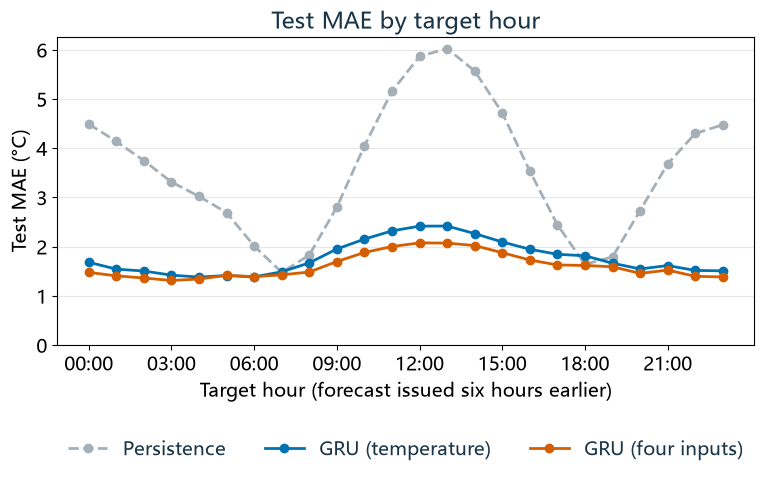

Test MAE (°C) by target hour:


,persistence,gru_temp,gru_multi
target_hour,,,
0,4.49,1.68,1.47
3,3.31,1.42,1.31
6,2.01,1.38,1.39
9,2.80,1.95,1.69
12,5.86,2.41,2.07
13,6.02,2.42,2.07
15,4.72,2.09,1.87
18,1.64,1.81,1.61
21,3.68,1.61,1.52


Failure cases (error = prediction - observation):


,,T_at_issue_c,rh_at_issue_pct,observed_c,persistence_error_c,dense_temp_error_c,gru_temp_error_c,gru_multi_error_c,dense_multi_error_c
target_time,issued_at,,,,,,,,
2025-04-20 13:00:00,2025-04-20 07:00:00,2.9,100.0,19.9,-17.0,-11.3,-9.7,-7.8,-10.6
2025-04-17 12:00:00,2025-04-17 06:00:00,11.0,93.1,12.1,-1.1,10.6,10.8,7.2,6.5
2025-08-16 12:00:00,2025-08-16 06:00:00,19.2,78.3,21.0,-1.8,6.2,6.1,8.9,8.9


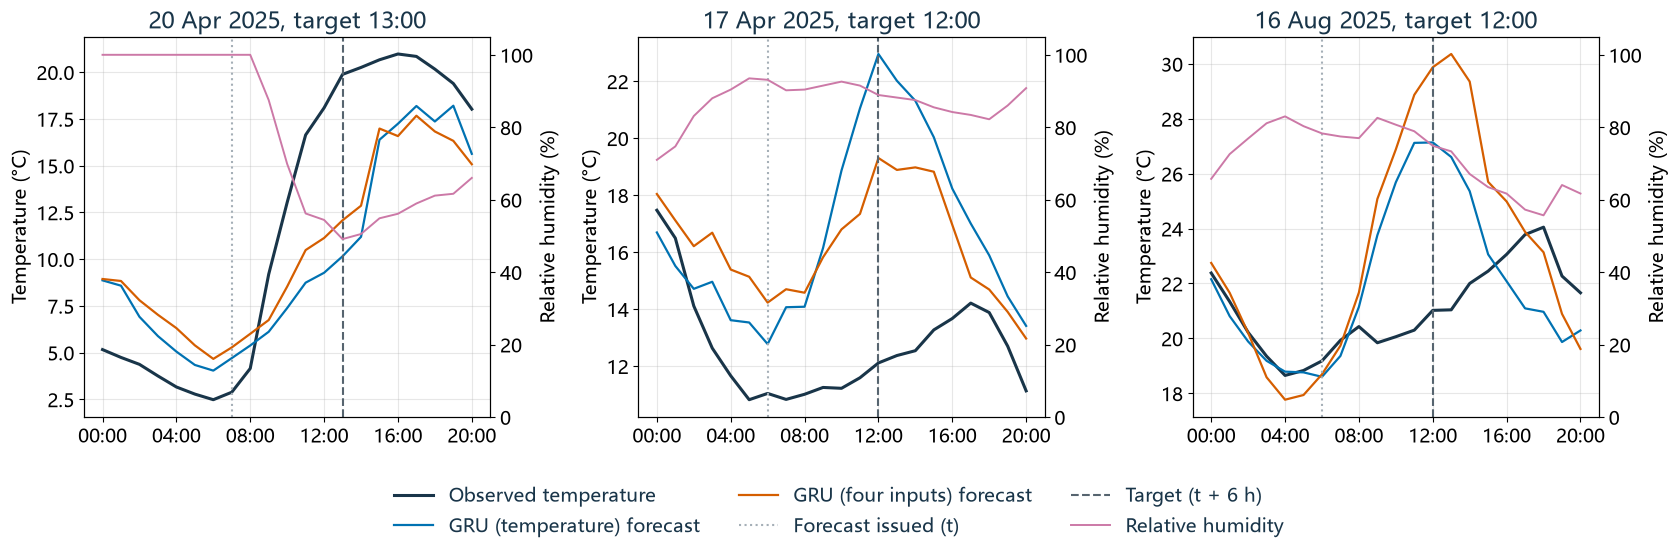

Midday targets (11:00-14:00) split by humidity when the forecast was issued:


,samples,gru_temp_mae_c,gru_multi_mae_c,gru_temp_bias_c,gru_multi_bias_c
"midday, rh at issue >= 95%",568.0,2.360,2.019,-0.679,-0.062
"midday, rh at issue < 95%",892.0,2.348,2.054,-0.459,-0.187


GRU (four inputs): MAE difference (saturated - not saturated) = -0.035 °C


In [14]:
# 14. Error analysis: time of day, failure cases and a humidity check (no training)
import matplotlib.dates as mdates

by_time = predictions.set_index("target_time")

# ---------- 14a. Test MAE by target hour ----------
hourly_mae = absolute.groupby(absolute.index.hour).mean()
hourly_mae.index.name = "target_hour"
hourly_mae.to_csv("outputs/hourly_mae.csv")
fig, ax = plt.subplots(figsize=(9, 4))
for name, (colour, line) in STYLE.items():
    ax.plot(hourly_mae.index, hourly_mae[name], marker="o", color=colour, linestyle=line, linewidth=2, label=NICE[name])
ax.set_xticks(range(0, 24, 3), [f"{h:02d}:00" for h in range(0, 24, 3)])
ax.set(xlabel="Target hour (forecast issued six hours earlier)", ylabel="Test MAE (°C)",
       title="Test MAE by target hour", ylim=(0, None))
ax.grid(axis="y", alpha=.3)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(.5, -.25))
fig.savefig("figures/hourly_mae.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Test MAE (°C) by target hour:")
display(hourly_mae.loc[[0, 3, 6, 9, 12, 13, 15, 18, 21], ["persistence", "gru_temp", "gru_multi"]].round(2))

# ---------- 14b. Failure cases ----------
# Chosen from outputs/worst_errors.csv (section 11): targets that several networks got badly wrong.
CASES = [pd.Timestamp(t) for t in ["2025-04-20 13:00", "2025-04-17 12:00", "2025-08-16 12:00"]]
rows = []
for case in CASES:
    issued = case - pd.Timedelta(hours=HORIZON)
    rows.append({"target_time": case, "issued_at": issued,
                 "T_at_issue_c": hourly.loc[issued, "T (degC)"], "rh_at_issue_pct": hourly.loc[issued, "rh (%)"],
                 "observed_c": by_time.loc[case, "observed_c"],
                 **{f"{name}_error_c": by_time.loc[case, name] - by_time.loc[case, "observed_c"] for name in names}})
failure_cases = pd.DataFrame(rows)
failure_cases.to_csv("outputs/failure_cases.csv", index=False)
print("Failure cases (error = prediction - observation):")
display(failure_cases.set_index(["target_time", "issued_at"]).round(1))

fig, axes = plt.subplots(1, len(CASES), figsize=(17, 4.8))
for ax, case in zip(axes, CASES):
    day = slice(case.normalize(), case.normalize() + pd.Timedelta(hours=20))
    observed = hourly.loc[day, "T (degC)"]
    ax.plot(observed.index, observed, color="#193549", linewidth=2.2, label="Observed temperature")
    for name in ["gru_temp", "gru_multi"]:
        colour, line = STYLE[name]
        ax.plot(by_time.loc[day].index, by_time.loc[day, name], color=colour, linestyle=line,
                linewidth=1.6, label=f"{NICE[name]} forecast")
    ax.axvline(case - pd.Timedelta(hours=HORIZON), color="#A5AFB7", linestyle=":", linewidth=1.5,
               label="Forecast issued (t)")
    ax.axvline(case, color="#56646F", linestyle="--", linewidth=1.5, label="Target (t + 6 h)")
    humidity = ax.twinx()
    humidity.plot(hourly.loc[day, "rh (%)"].index, hourly.loc[day, "rh (%)"], color="#CC79A7",
                  linewidth=1.4, label="Relative humidity")
    humidity.set(ylim=(0, 105), ylabel="Relative humidity (%)")
    ax.set(title=f"{case:%d %b %Y}, target {case:%H:%M}", ylabel="Temperature (°C)")
    ax.xaxis.set_major_locator(mdates.HourLocator(byhour=range(0, 24, 4)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.grid(alpha=.3)
handles = axes[0].get_legend_handles_labels()
extra = humidity.get_legend_handles_labels()
fig.tight_layout()
fig.legend(handles[0] + extra[0], handles[1] + extra[1], loc="upper center", bbox_to_anchor=(.5, 0),
           ncol=3, frameon=False)
fig.savefig("figures/failure_cases.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

# ---------- 14c. Does a saturated morning predict a bad midday forecast? ----------
# Tests the fog / low-cloud explanation suggested by the failure cases across all midday targets.
rh_at_issue = hourly["rh (%)"].reindex(by_time.index - pd.Timedelta(hours=HORIZON)).to_numpy()
midday = np.asarray(by_time.index.hour.isin([11, 12, 13, 14]))
groups = {"midday, rh at issue >= 95%": midday & (rh_at_issue >= 95),
          "midday, rh at issue < 95%": midday & (rh_at_issue < 95)}
saturation_check = pd.DataFrame({
    label: {"samples": int(mask.sum()),
            **{f"{name}_mae_c": float(absolute[name].to_numpy()[mask].mean()) for name in ["gru_temp", "gru_multi"]},
            **{f"{name}_bias_c": float(errors[name].to_numpy()[mask].mean()) for name in ["gru_temp", "gru_multi"]}}
    for label, mask in groups.items()}).T
saturation_check.to_csv("outputs/midday_saturation_check.csv")
print("Midday targets (11:00-14:00) split by humidity when the forecast was issued:")
display(saturation_check.round(3))
gap = saturation_check["gru_multi_mae_c"].iloc[0] - saturation_check["gru_multi_mae_c"].iloc[1]
print(f"{NICE['gru_multi']}: MAE difference (saturated - not saturated) = {gap:+.3f} °C")

# 15. Feature ablation study

Retrain the multivariate GRU on nine input subsets (leave-one-out and add-one) with three seeds. Excluded standardized channels are set to zero, so every configuration keeps the same architecture. Requires sections 1-4 in the same kernel (earlier models need not be retrained). Early stopping uses validation data only; the 2025 test set is evaluated after all models are frozen.

In fast mode (`RETRAIN = False`) this cell does not train: it reloads the most recent completed run in `outputs/feature_ablation/` and redraws its tables and figure.

RETRAIN = False: reusing saved ablation results from outputs\feature_ablation\20261016T040200_432984Z


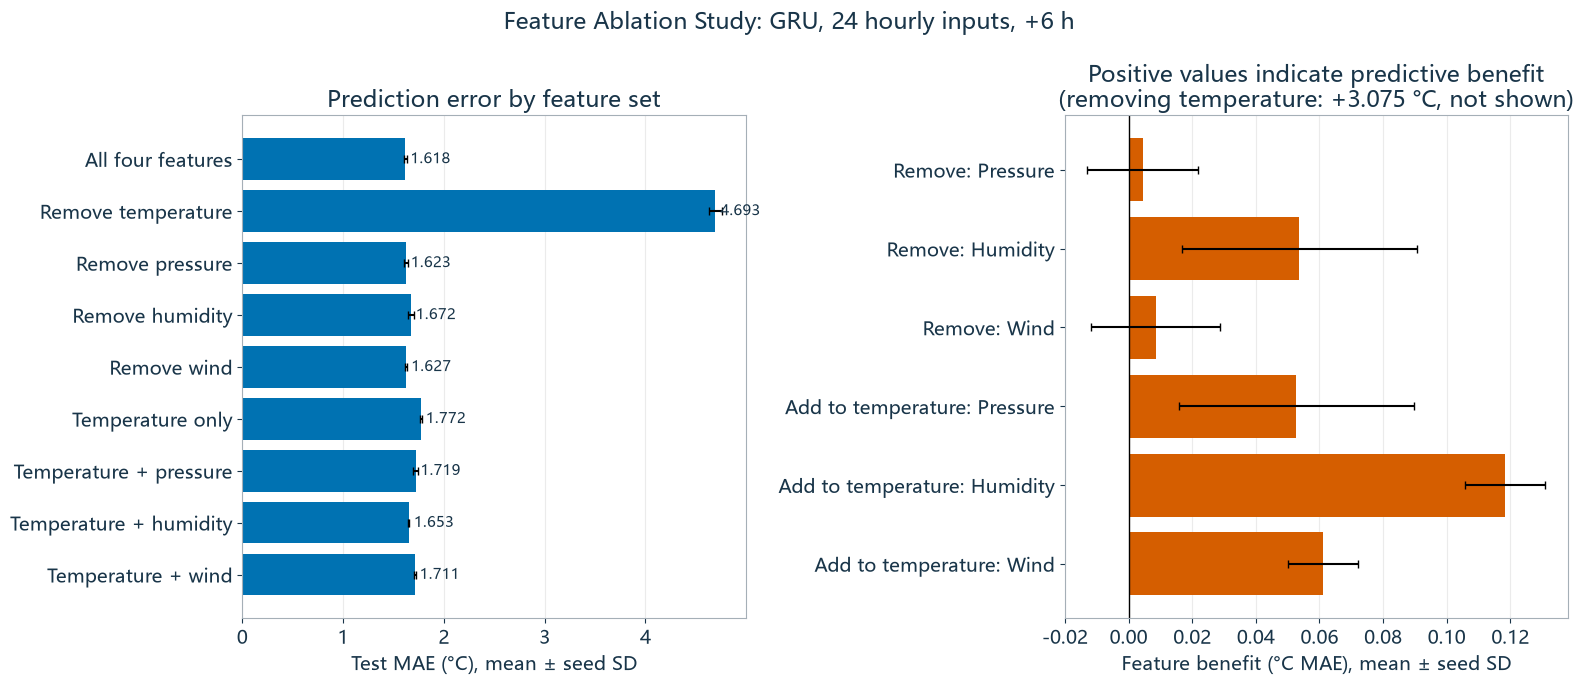


Test metrics:


,config_id,n_seeds,n_samples,n_parameters,mae_mean_c,mae_std_c,rmse_mean_c,rmse_std_c,bias_mean_c,training_seconds_mean
0,full,3,8760,3681,1.6184,0.0123,2.1070,0.0155,0.1640,77.6922
1,without_temperature,3,8760,3681,4.6933,0.0635,5.8181,0.0581,0.9607,39.2373
2,without_pressure,3,8760,3681,1.6229,0.0195,2.1213,0.0180,0.0706,89.6390
3,without_humidity,3,8760,3681,1.6721,0.0298,2.1635,0.0271,0.0744,90.5116
4,without_wind,3,8760,3681,1.6270,0.0104,2.1529,0.0087,0.0439,92.2879
5,temperature_only,3,8760,3681,1.7718,0.0092,2.3195,0.0146,0.0293,92.4273
6,temperature_pressure,3,8760,3681,1.7190,0.0277,2.2436,0.0260,0.2461,81.9298
7,temperature_humidity,3,8760,3681,1.6535,0.0052,2.1992,0.0097,0.0101,101.6794
8,temperature_wind,3,8760,3681,1.7106,0.0099,2.2089,0.0131,0.1384,87.1928



Feature predictive benefits:


,effect_type,feature,n_seeds,delta_mae_mean_c,delta_mae_std_c,relative_effect_mean_pct
0,leave_one_out,Temperature,3,3.0749,0.0757,190.0235
1,leave_one_out,Pressure,3,0.0045,0.0174,0.2796
2,leave_one_out,Humidity,3,0.0537,0.0370,3.3232
3,leave_one_out,Wind,3,0.0085,0.0203,0.5322
4,add_one,Pressure,3,0.0528,0.0369,2.9717
5,add_one,Humidity,3,0.1183,0.0127,6.6738
6,add_one,Wind,3,0.0611,0.0111,3.4494



Paired seven-day block intervals:


,effect_type,feature,delta_mae_c,ci_low_c,ci_high_c,block_days,bootstrap_repetitions,interval_scope
0,leave_one_out,Temperature,3.0749,2.6484,3.4789,7,2000,test dates conditional on fitted models
1,leave_one_out,Pressure,0.0045,-0.0291,0.0357,7,2000,test dates conditional on fitted models
2,leave_one_out,Humidity,0.0537,0.0283,0.0792,7,2000,test dates conditional on fitted models
3,leave_one_out,Wind,0.0085,-0.0174,0.0337,7,2000,test dates conditional on fitted models
4,add_one,Pressure,0.0528,0.0130,0.0861,7,2000,test dates conditional on fitted models
5,add_one,Humidity,0.1183,0.0881,0.1464,7,2000,test dates conditional on fitted models
6,add_one,Wind,0.0611,0.0259,0.0931,7,2000,test dates conditional on fitted models



Results saved to: C:\Users\auyhp\OneDrive\Desktop\504-final\1015\final_report\outputs\feature_ablation\20261016T040200_432984Z


In [15]:
# Feature ablation study: requires FEATURES and splits from steps 1-4 (no model training needed).
# Every configuration uses the same four-channel GRU; excluded standardized channels are set to zero.
assert "splits" in globals(), "Run sections 1-4 first: setup must configure TensorFlow before it is imported."
import math
from datetime import datetime, timezone

# ---------- 1. Protocol ----------
SEEDS, EPOCHS, BATCH, PATIENCE, LR = [504, 505, 506], 30, 64, 5, 0.001
NAMES = ["temperature", "pressure", "humidity", "wind"]
CONFIGS = {  # name: (retained channels, plot label)
    "full": ((0, 1, 2, 3), "All four features"),
    **{f"without_{n}": (tuple(j for j in range(4) if j != i), f"Remove {n}") for i, n in enumerate(NAMES)},
    "temperature_only": ((0,), "Temperature only"),
    **{f"temperature_{n}": ((0, i), f"Temperature + {n}") for i, n in enumerate(NAMES) if i},
}
# Effect = MAE(left) - MAE(right); positive values mean the feature helps in both comparison types.
COMPARISONS = ([("leave_one_out", n.title(), f"without_{n}", "full") for n in NAMES]
               + [("add_one", n.title(), "temperature_only", f"temperature_{n}") for n in NAMES[1:]])

if RETRAIN:
    OUT = Path("outputs/feature_ablation") / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    for sub in ("models", "figures"):
        (OUT / sub).mkdir(parents=True, exist_ok=True)

    protocol = {
        "status": "planned", "seeds": SEEDS, "max_epochs": EPOCHS, "batch_size": BATCH,
        "learning_rate": LR, "loss": "mse",
        "early_stopping": {"monitor": "val_loss", "patience": PATIENCE, "restore_best_weights": True},
        "architecture": "Input(24,4) -> GRU(32) -> Dense(1)", "feature_order": FEATURES,
        "retained_features": {c: [FEATURES[i] for i in kept] for c, (kept, _) in CONFIGS.items()},
        "masking": "Excluded standardized channels are set to zero during training, validation and testing.",
        "split_sample_counts": {k: len(splits[k]["y"]) for k in ("train", "val", "test")},
        "target_unit": "degrees Celsius", "tensorflow_version": tf.__version__,
        "interpretation": "Exploratory follow-up on the previously inspected 2025 test period; "
                          "no test-based hyperparameter tuning.",
    }

    def save_protocol(status, **extra):
        protocol.update(status=status, **extra)
        (OUT / "protocol.json").write_text(json.dumps(protocol, ensure_ascii=False, indent=2), encoding="utf-8")

    save_protocol("planned")

    # ---------- 2. Helpers ----------
    def masked(split, kept):
        """Copy of the inputs with non-retained channels set to zero."""
        return np.where(np.isin(np.arange(4), kept), splits[split]["X"], np.float32(0))

    def make_ds(x, y=None, seed=None):
        """Batched dataset with bounded threading; shuffle only when a seed is given."""
        ds = tf.data.Dataset.from_tensor_slices(x if y is None else (x, y))
        opt = tf.data.Options()
        opt.threading.private_threadpool_size = opt.threading.max_intra_op_parallelism = 1
        ds = ds.with_options(opt)
        if seed is not None:
            ds = ds.shuffle(len(x), seed=seed, reshuffle_each_iteration=True)
        return ds.batch(BATCH).prefetch(1)

    def build_model(name):
        model = tf.keras.Sequential([tf.keras.layers.Input((24, 4)), tf.keras.layers.GRU(32),
                                     tf.keras.layers.Dense(1)], name=name)
        model.compile(optimizer=tf.keras.optimizers.Adam(LR), loss="mse", metrics=["mae"], jit_compile=False)
        return model

    def ab_errors(observed, predicted):
        e = np.asarray(predicted, np.float64).ravel() - np.asarray(observed, np.float64).ravel()
        return {"n_samples": len(e), "mae_c": float(np.mean(np.abs(e))),
                "rmse_c": float(np.sqrt(np.mean(e ** 2))), "bias_c": float(np.mean(e))}

    # ---------- 3. Train all configurations (early stopping on validation only) ----------
    ab_records, ab_val_rows = [], []
    for seed in SEEDS:
        for cid, (kept, _) in CONFIGS.items():
            tf.keras.backend.clear_session()
            tf.keras.utils.set_random_seed(seed)  # same initialization and shuffling across configurations
            val_x = masked("val", kept)
            train_ds = make_ds(masked("train", kept), splits["train"]["y"], seed)
            val_ds = make_ds(val_x, splits["val"]["y"])
            print(f"\nTraining: seed={seed}, configuration={cid}")
            model = build_model(cid)
            start = time.perf_counter()
            history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, shuffle=False, verbose=2, callbacks=[
                tf.keras.callbacks.EarlyStopping("val_loss", patience=PATIENCE, restore_best_weights=True)])
            seconds = time.perf_counter() - start
            model_path = OUT / "models" / f"{cid}_seed_{seed}.keras"
            model.save(model_path)
            val_pred = model.predict(make_ds(val_x), verbose=0)
            hist = pd.DataFrame(history.history)
            hist.insert(0, "epoch", np.arange(1, len(hist) + 1))
            hist.to_csv(OUT / f"history_{cid}_seed_{seed}.csv", index=False)
            rec = {"seed": seed, "config_id": cid, "n_parameters": int(model.count_params()),
                   "epochs_run": len(hist), "best_epoch": int(np.argmin(hist["val_loss"]) + 1),
                   "training_seconds": seconds, "model_path": str(model_path)}
            ab_records.append(rec)
            ab_val_rows.append({**rec, **ab_errors(splits["val"]["y"], val_pred)})

    pd.DataFrame(ab_records).to_csv(OUT / "training_records.csv", index=False)
    pd.DataFrame(ab_val_rows).to_csv(OUT / "validation_results.csv", index=False)
    save_protocol("models_frozen")  # the test set is used only after all models are frozen

    # ---------- 4. Evaluate on the shared test targets ----------
    test_y = np.asarray(splits["test"]["y"], np.float64)
    test_times = pd.DatetimeIndex(splits["test"]["times"])
    ab_preds, ab_test_rows = {}, []
    for rec in ab_records:  # seeds outer, configurations inner
        tf.keras.backend.clear_session()
        model = tf.keras.models.load_model(rec["model_path"], compile=False)
        p = model.predict(make_ds(masked("test", CONFIGS[rec["config_id"]][0])), verbose=0).ravel()
        ab_preds[rec["seed"], rec["config_id"]] = p
        ab_test_rows.append({**rec, **ab_errors(test_y, p)})
    for seed in SEEDS:
        pd.DataFrame({"target_time": test_times, "observed_c": test_y,
                      **{c: ab_preds[seed, c] for c in CONFIGS}}).to_csv(OUT / f"test_predictions_seed_{seed}.csv", index=False)

    ab_results = pd.DataFrame(ab_test_rows)
    ab_results.to_csv(OUT / "metrics_by_seed.csv", index=False)
    ab_summary = (ab_results.groupby("config_id", sort=False)  # std is the between-seed SD, not a CI
                  .agg(n_seeds=("seed", "count"), n_samples=("n_samples", "first"),
                       n_parameters=("n_parameters", "first"), mae_mean_c=("mae_c", "mean"),
                       mae_std_c=("mae_c", "std"), rmse_mean_c=("rmse_c", "mean"), rmse_std_c=("rmse_c", "std"),
                       bias_mean_c=("bias_c", "mean"), training_seconds_mean=("training_seconds", "mean"))
                  .reindex(list(CONFIGS)).reset_index())
    ab_summary.to_csv(OUT / "metrics_summary.csv", index=False)

    # ---------- 5. Predictive benefit of each feature ----------
    ab_mae = ab_results.set_index(["seed", "config_id"])["mae_c"]
    ab_effects = pd.DataFrame([
        {"seed": s, "effect_type": kind, "feature": feat, "left_config": l, "right_config": r,
         "delta_mae_c": (d := ab_mae[s, l] - ab_mae[s, r]),
         # Leave-one-out is relative to the full model; add-one is relative to temperature only.
         "relative_effect_pct": 100 * d / (ab_mae[s, r] if kind == "leave_one_out" else ab_mae[s, l])}
        for s in SEEDS for kind, feat, l, r in COMPARISONS])
    ab_effects.to_csv(OUT / "feature_effects_by_seed.csv", index=False)
    ab_effect_summary = (ab_effects.groupby(["effect_type", "feature"], sort=False)
                         .agg(n_seeds=("seed", "count"), delta_mae_mean_c=("delta_mae_c", "mean"),
                              delta_mae_std_c=("delta_mae_c", "std"),
                              relative_effect_mean_pct=("relative_effect_pct", "mean"))
                         .reset_index())
    ab_effect_summary.to_csv(OUT / "feature_effects_summary.csv", index=False)

    # ---------- 6. Paired seven-day block bootstrap ----------
    # Per-target absolute errors are averaged over seeds (not an ensemble prediction). Intervals reflect
    # test-date variation only; training randomness is shown by the seed SD. Exploratory, unadjusted.
    ab_mean_loss = {c: np.mean([np.abs(ab_preds[s, c].astype(np.float64) - test_y) for s in SEEDS], axis=0)
                    for c in CONFIGS}

    def block_interval(diff, times, block_days=7, reps=2000, seed=504):
        """Resample contiguous day blocks weighted by daily counts; missing days stay empty."""
        daily = pd.Series(diff).groupby(pd.DatetimeIndex(times).normalize()).agg(["sum", "count"])
        daily = daily.reindex(pd.date_range(daily.index.min(), daily.index.max(), freq="D"), fill_value=0)
        sums, counts = daily["sum"].to_numpy(np.float64), daily["count"].to_numpy(np.float64)
        n = len(daily)
        L = min(block_days, n)
        rng = np.random.default_rng(seed)
        starts = np.stack([rng.integers(0, n - L + 1, size=math.ceil(n / L)) for _ in range(reps)])
        days = (starts[:, :, None] + np.arange(L)).reshape(reps, -1)[:, :n]
        total = counts[days].sum(axis=1)
        vals = sums[days].sum(axis=1)[total > 0] / total[total > 0]
        low, high = np.quantile(vals, [0.025, 0.975])
        return float(low), float(high)

    ab_bootstrap = pd.DataFrame([
        {"effect_type": kind, "feature": feat, "delta_mae_c": float(np.mean(diff)),
         **dict(zip(["ci_low_c", "ci_high_c"], block_interval(diff, test_times))),
         "block_days": 7, "bootstrap_repetitions": 2000,
         "interval_scope": "test dates conditional on fitted models"}
        for kind, feat, l, r in COMPARISONS for diff in [ab_mean_loss[l] - ab_mean_loss[r]]])
    ab_bootstrap.to_csv(OUT / "paired_block_bootstrap.csv", index=False)

else:
    # Fast mode: reuse the most recent completed ablation run instead of retraining 27 GRUs.
    OUT = sorted(p for p in Path("outputs/feature_ablation").iterdir()
                 if (p / "paired_block_bootstrap.csv").exists())[-1]
    ab_summary = pd.read_csv(OUT / "metrics_summary.csv")
    ab_effect_summary = pd.read_csv(OUT / "feature_effects_summary.csv")
    ab_bootstrap = pd.read_csv(OUT / "paired_block_bootstrap.csv")
    print("RETRAIN = False: reusing saved ablation results from", OUT)

# ---------- 7. Plot ----------
def hbar(ax, labels, vals, err, color, xlabel, title):
    pos = np.arange(len(labels))
    ax.barh(pos, vals, xerr=err.fillna(0), color=color, capsize=3)
    ax.set_yticks(pos, labels)
    ax.invert_yaxis()
    ax.set(xlabel=xlabel, title=title)
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)

# Dark text on the white figure background (section 12 sets a white facecolor); palette shared with the slides.
plt.rcParams.update({"axes.labelcolor": "#193549", "xtick.color": "#193549", "ytick.color": "#193549",
                     "axes.titlecolor": "#193549", "axes.edgecolor": "#A5AFB7"})
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
hbar(axes[0], [CONFIGS[c][1] for c in ab_summary["config_id"]], ab_summary["mae_mean_c"], ab_summary["mae_std_c"],
     "#0072B2", "Test MAE (°C), mean ± seed SD", "Prediction error by feature set")
for position, value in enumerate(ab_summary["mae_mean_c"]):
    axes[0].text(value + .05, position, f"{value:.3f}", va="center", fontsize=11)
# Removing temperature (+3 °C) would dwarf the other effects, so it is reported in the title instead of as a bar.
others = ab_effect_summary[ab_effect_summary["feature"] != "Temperature"]
removal = ab_effect_summary.loc[ab_effect_summary["feature"] == "Temperature", "delta_mae_mean_c"].iloc[0]
benefit = others["delta_mae_mean_c"]
hbar(axes[1], [("Remove: " if t == "leave_one_out" else "Add to temperature: ") + f
               for t, f in zip(others["effect_type"], others["feature"])],
     benefit, others["delta_mae_std_c"], ["#D55E00" if v >= 0 else "#A5AFB7" for v in benefit],
     "Feature benefit (°C MAE), mean ± seed SD",
     f"Positive values indicate predictive benefit\n(removing temperature: {removal:+.3f} °C, not shown)")
axes[1].axvline(0, color="black", linewidth=1)
fig.suptitle("Feature Ablation Study: GRU, 24 hourly inputs, +6 h")
fig.tight_layout()
fig.savefig(OUT / "figures" / "feature_ablation.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

# ---------- 8. Report ----------
if RETRAIN:
    save_protocol("completed", completed_utc=datetime.now(timezone.utc).isoformat())
for title, table in [("Test metrics", ab_summary), ("Feature predictive benefits", ab_effect_summary),
                     ("Paired seven-day block intervals", ab_bootstrap)]:
    print(f"\n{title}:")
    display(table.round(4))
print("\nResults saved to:", OUT.resolve())


# 16. Final summary

Collect the key results in one place without retraining: the 2025 test table for all five methods, answers to the three research questions with their paired daily intervals, and a readable feature-ablation summary figure (uses section 15 if it ran in this kernel, otherwise the most recent saved ablation run).

Outputs: `outputs/final_summary.csv`, `figures/feature_ablation_summary.png`.

Test 2025, all methods (sorted by MAE):


,mae_c,rmse_c,bias_c,parameters,vs_persistence_pct
model,,,,,
gru_multi,1.604,2.091,0.249,3681,54.934
dense_multi,1.663,2.153,0.109,3137,53.276
gru_temp,1.771,2.308,-0.049,3393,50.256
dense_temp,1.793,2.333,0.016,833,49.643
persistence,3.560,4.680,-0.002,0,0.000


Best model: Multivariate GRU, test MAE 1.604 °C
RQ1 - Multivariate GRU vs Persistence: 54.9% lower MAE (interval excludes 0)
RQ2 - Temperature GRU vs Temperature Dense: 1.2% lower MAE (interval includes 0) | Multivariate GRU vs Multivariate Dense: 3.5% lower MAE (interval excludes 0)
RQ3 - Multivariate GRU vs Temperature GRU: 9.4% lower MAE (interval excludes 0) | Multivariate Dense vs Temperature Dense: 7.2% lower MAE (interval excludes 0)
Hardest target hour for Multivariate GRU: 12:00 (MAE 2.07 °C)
Most useful extra input (add-one, 3 seeds): Humidity (+0.118 °C)


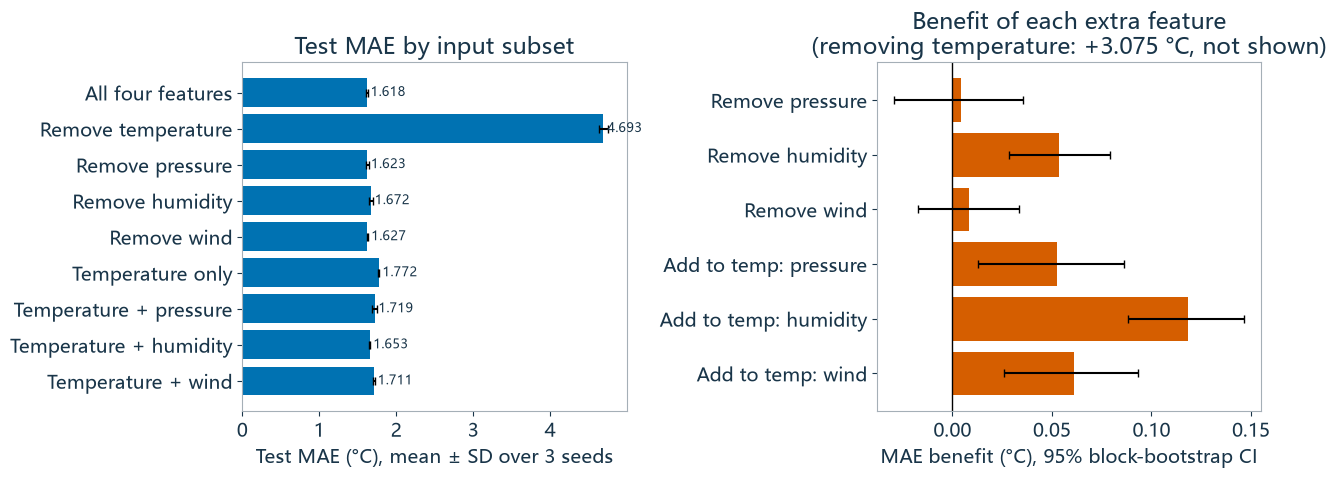

In [16]:
# 16. Final summary: answers to the research questions (no training; reuses results from sections 10-15)
summary = results[["mae_c", "rmse_c", "bias_c", "parameters"]].copy()
summary["vs_persistence_pct"] = 100 * (1 - summary.mae_c / summary.loc["persistence", "mae_c"])
summary = summary.sort_values("mae_c")
summary.to_csv("outputs/final_summary.csv")
print("Test 2025, all methods (sorted by MAE):")
display(summary.round(3))

cmp = comparison_results.set_index(["candidate", "reference"])


def verdict(candidate, reference):
    row = cmp.loc[(candidate, reference)]
    sure = "interval includes 0" if row.ci_low_c <= 0 <= row.ci_high_c else "interval excludes 0"
    return f"{labels[candidate]} vs {labels[reference]}: {row.reduction_pct:.1f}% lower MAE ({sure})"


best = summary.index[0]
print(f"Best model: {labels[best]}, test MAE {summary.loc[best, 'mae_c']:.3f} °C")
print("RQ1 -", verdict("gru_multi", "persistence"))
print("RQ2 -", verdict("gru_temp", "dense_temp"), "|", verdict("gru_multi", "dense_multi"))
print("RQ3 -", verdict("gru_multi", "gru_temp"), "|", verdict("dense_multi", "dense_temp"))
worst_hour = hourly_mae["gru_multi"].idxmax()
print(f"Hardest target hour for {labels['gru_multi']}: {worst_hour:02d}:00 "
      f"(MAE {hourly_mae.loc[worst_hour, 'gru_multi']:.2f} °C)")

# Feature ablation summary: results from section 15, or the most recent saved run if section 15 was skipped.
if "ab_bootstrap" not in globals():
    runs = sorted(p for p in Path("outputs/feature_ablation").iterdir() if (p / "paired_block_bootstrap.csv").exists())
    if runs:
        ab_summary = pd.read_csv(runs[-1] / "metrics_summary.csv")
        ab_bootstrap = pd.read_csv(runs[-1] / "paired_block_bootstrap.csv")
        print("Using saved ablation results from", runs[-1])


def subset_label(config_id):
    if config_id == "full":
        return "All four features"
    if config_id == "temperature_only":
        return "Temperature only"
    kind, feature = config_id.split("_", 1)
    return f"Remove {feature}" if kind == "without" else f"Temperature + {feature}"


if "ab_bootstrap" in globals():
    top = ab_bootstrap[ab_bootstrap.effect_type == "add_one"].sort_values("delta_mae_c").iloc[-1]
    print(f"Most useful extra input (add-one, 3 seeds): {top.feature} ({top.delta_mae_c:+.3f} °C)")

    readable = {"figure.facecolor": "white", "axes.facecolor": "white", "text.color": "#193549",
                "axes.labelcolor": "#193549", "axes.titlecolor": "#193549", "xtick.color": "#193549",
                "ytick.color": "#193549", "axes.edgecolor": "#A5AFB7"}
    with plt.rc_context(readable):
        fig, (left, right) = plt.subplots(1, 2, figsize=(13, 5))
        subsets = [subset_label(c) for c in ab_summary.config_id]
        left.barh(subsets, ab_summary.mae_mean_c, xerr=ab_summary.mae_std_c, color="#0072B2", capsize=3)
        left.invert_yaxis()
        left.set(xlabel="Test MAE (°C), mean ± SD over 3 seeds", title="Test MAE by input subset")
        for position, value in enumerate(ab_summary.mae_mean_c):
            left.text(value + .05, position, f"{value:.3f}", va="center", fontsize=9)

        effects = ab_bootstrap[ab_bootstrap.feature != "Temperature"]
        effect_names = [("Remove " if kind == "leave_one_out" else "Add to temp: ") + feature.lower()
                        for kind, feature in zip(effects.effect_type, effects.feature)]
        error = np.vstack([effects.delta_mae_c - effects.ci_low_c, effects.ci_high_c - effects.delta_mae_c])
        right.barh(effect_names, effects.delta_mae_c, xerr=error, color="#D55E00", capsize=3)
        right.axvline(0, color="black", linewidth=1)
        right.invert_yaxis()
        removal = ab_bootstrap.loc[ab_bootstrap.feature == "Temperature", "delta_mae_c"].iloc[0]
        right.set(xlabel="MAE benefit (°C), 95% block-bootstrap CI",
                  title=f"Benefit of each extra feature\n(removing temperature: {removal:+.3f} °C, not shown)")
        fig.tight_layout()
        fig.savefig("figures/feature_ablation_summary.png", dpi=200, bbox_inches="tight")
        plt.show()
        plt.close(fig)